# Notebook 06 - Synthetic Signal Analysis

This notebook analyzes invented values from anonymous signal channels. Results are illustrative and are not sourced from an organization or operating asset.

## Analysis step 2

Import anomaly detection methods and set paths for cleaned signals, labels, and saved outputs.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.covariance import LedoitWolf
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer

HERE = Path.cwd().resolve()
ROOT = None
INTERIM = None
PROCESSED = None

# First, look for the standard project folder structure.
for candidate in [HERE, *HERE.parents]:
    interim_candidate = candidate / 'data' / 'interim'
    processed_candidate = candidate / 'data' / 'processed'

    if (
        (interim_candidate / 'channel_clean.csv').is_file()
        and (processed_candidate / 'features_labels.csv').is_file()
    ):
        ROOT = candidate
        INTERIM = interim_candidate
        PROCESSED = processed_candidate
        break

# If the files are uploaded directly to Colab, use their current folder.
if ROOT is None:
    for candidate in [HERE, *HERE.parents]:
        if (
            (candidate / 'channel_clean.csv').is_file()
            and (candidate / 'features_labels.csv').is_file()
        ):
            ROOT = candidate
            INTERIM = candidate
            PROCESSED = candidate
            break

if ROOT is None:
    raise FileNotFoundError(
        'Could not find channel_clean.csv and features_labels.csv. '
        'Make sure all four input files are uploaded.'
    )

FIG_DIR = ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

OUT_DIR = ROOT / 'reports' / 'tables'
OUT_DIR.mkdir(parents=True, exist_ok=True)

FIT_FRACTION = 0.70
ALARM_QUANTILES = [0.95, 0.975, 0.99]
SUSTAIN_WINDOW = 7
SUSTAIN_COUNT = 5
RANDOM_STATE = 42

print('Project path:', ROOT)
print('INTERIM:', INTERIM)
print('PROCESSED:', PROCESSED)

Project path: D:\ML_NTI\Predictive Maintanance\predictive-maintenance
INTERIM: D:\ML_NTI\Predictive Maintanance\predictive-maintenance\data\interim
PROCESSED: D:\ML_NTI\Predictive Maintanance\predictive-maintenance\data\processed


## Analysis step 3

Set the calibration period, candidate anomaly methods, and alert persistence requirements. Thresholds are learned from baseline data so later observations can be compared with a historical reference.

In [2]:
clean = pd.read_csv(INTERIM / 'channel_clean.csv', index_col=0, parse_dates=True)
scaled = pd.read_csv(INTERIM / 'channel_scaled.csv', index_col=0, parse_dates=True)
table = pd.read_csv(PROCESSED / 'features_labels.csv', index_col=0, parse_dates=True)
with open(PROCESSED / 'label_config.json') as f:
    cfg = json.load(f)

assert clean.index.equals(scaled.index) and clean.index.equals(table.index)
CORE = cfg['core_sensors']
assert all(c in scaled.columns for c in CORE), 'A core sensor is missing from channel_scaled.csv'

state_cols = ['is_shutdown', 'is_restart', 'is_suspect', 'is_baseline', 'core_complete', 'segment_id']
state = clean[state_cols].copy()
for c in state_cols[:-1]:
    state[c] = state[c].astype(bool)
state['segment_id'] = pd.to_numeric(state['segment_id'], errors='coerce')
X = scaled[CORE].astype(float)

valid = (~state['is_shutdown'] & ~state['is_restart'] & ~state['is_suspect']
         & state['core_complete'] & X.notna().all(axis=1))
baseline = valid & state['is_baseline'] & (clean.index.year == 2032)
baseline_dates = clean.index[baseline]
assert len(baseline_dates) >= 100, 'Too few eligible healthy-reference days to split fit and calibration.'
cut_pos = int(np.floor(len(baseline_dates) * FIT_FRACTION))
fit_end = baseline_dates[cut_pos - 1]
fit_mask = baseline & (clean.index <= fit_end)
cal_mask = baseline & (clean.index > fit_end)
assert fit_mask.sum() >= 50 and cal_mask.sum() >= 30

print('eligible 2032 baseline:', int(baseline.sum()))
print('fit period:', clean.index[fit_mask].min().date(), 'to', clean.index[fit_mask].max().date(), '| rows:', int(fit_mask.sum()))
print('calibration period:', clean.index[cal_mask].min().date(), 'to', clean.index[cal_mask].max().date(), '| rows:', int(cal_mask.sum()))
print('eligible 2033 operating days:', int((valid & (clean.index.year == 2033)).sum()))
print('failure date in config:', cfg['failure_date_used'], '| provisional:', cfg['failure_date_provisional'])

eligible 2032 baseline: 366
fit period: 2032-01-01 to 2032-09-12 | rows: 256
calibration period: 2032-09-13 to 2032-12-31 | rows: 110
eligible 2033 operating days: 340
failure date in config: 2033-12-31 | provisional: True


## Analysis step 4

Load cleaned and scaled signals, feature labels, and configuration; align their time indexes and select the core channels used for anomaly scoring.

In [3]:
imputer = SimpleImputer(strategy='median')
X_fit = imputer.fit_transform(X.loc[fit_mask])
X_all = pd.DataFrame(imputer.transform(X), index=X.index, columns=CORE)

models = {}

# Higher scores always mean more anomalous.
lw = LedoitWolf().fit(X_fit)
models['Ledoit-Wolf distance'] = lambda a: np.sqrt(np.maximum(lw.mahalanobis(a), 0))

iso = IsolationForest(n_estimators=300, contamination='auto', random_state=RANDOM_STATE)
iso.fit(X_fit)
models['Isolation Forest'] = lambda a: -iso.score_samples(a)

pca = PCA(n_components=0.90, svd_solver='full', random_state=RANDOM_STATE)
pca.fit(X_fit)

def pca_reconstruction_error(a):
    z = pca.transform(a)
    reconstructed = pca.inverse_transform(z)
    return np.mean((a - reconstructed) ** 2, axis=1)

models['PCA reconstruction error'] = pca_reconstruction_error

scores = pd.DataFrame(index=X.index)
for name, scorer in models.items():
    scores[name] = np.nan
    scores.loc[valid, name] = scorer(X_all.loc[valid].to_numpy())

print('PCA components retained:', pca.n_components_, 'of', len(CORE))
print('scores computed for eligible operating rows:', int(valid.sum()))

PCA components retained: 12 of 14
scores computed for eligible operating rows: 706


## Analysis step 5

Fit the imputer and anomaly detectors using baseline-period observations, then score the full series. The score columns measure unusualness under each detector; larger scores indicate observations farther from the fitted reference.

In [4]:
def sustained_by_segment(raw_alarm, segment_id):
    out = pd.Series(False, index=raw_alarm.index)

    for sid in segment_id.dropna().unique():
        idx = segment_id.index[segment_id.eq(sid)]
        s = raw_alarm.reindex(idx).fillna(False).astype(int)
        sustained = s.rolling(
            SUSTAIN_WINDOW,
            min_periods=SUSTAIN_WINDOW
        ).sum() >= SUSTAIN_COUNT
        out.loc[idx] = sustained.to_numpy()

    return out


records = []
alerts = {}

for model_name in scores.columns:
    cal_scores = scores.loc[cal_mask, model_name].dropna()

    for q in ALARM_QUANTILES:
        threshold = float(cal_scores.quantile(q))
        raw = (scores[model_name] > threshold) & valid
        sustained = sustained_by_segment(raw, state['segment_id'])
        alerts[(model_name, q)] = sustained

        # Count starts of sustained alarm runs, resetting at operating-segment boundaries.
        episode = pd.Series(False, index=sustained.index)

        for sid in state['segment_id'].dropna().unique():
            idx = state.index[state['segment_id'].eq(sid)]
            seg_alarm = sustained.loc[idx]
            episode.loc[idx] = seg_alarm & ~seg_alarm.shift(1, fill_value=False)

        records.append({
            'model': model_name,
            'calibration_quantile': q,
            'threshold': threshold,
            'calibration_exceedance_days': int(raw.loc[cal_mask].sum()),
            'calibration_sustained_days': int(sustained.loc[cal_mask].sum()),
            'calibration_alarm_starts': int(episode.loc[cal_mask].sum()),
            'eligible_calibration_days': int(cal_mask.sum()),
            'eligible_2033_days': int((valid & (clean.index.year == 2033)).sum()),
            '2033_sustained_days': int(
                (sustained & valid & (clean.index.year == 2033)).sum()
            ),
            '2033_alarm_starts': int(
                (episode & valid & (clean.index.year == 2033)).sum()
            ),
        })

summary = pd.DataFrame(records)
summary

,model,calibration_quantile,threshold,calibration_exceedance_days,calibration_sustained_days,calibration_alarm_starts,eligible_calibration_days,eligible_2033_days,2033_sustained_days,2033_alarm_starts
0,Ledoit-Wolf distance,0.950,4.656557,6,0,0,110,340,324,4
1,Ledoit-Wolf distance,0.975,4.979209,3,0,0,110,340,324,4
2,Ledoit-Wolf distance,0.990,5.039323,2,0,0,110,340,324,4
3,Isolation Forest,0.950,0.483833,6,0,0,110,340,136,17
4,Isolation Forest,0.975,0.495623,3,0,0,110,340,59,9
5,Isolation Forest,0.990,0.497887,2,0,0,110,340,31,6
6,PCA reconstruction error,0.950,0.209368,6,0,0,110,340,324,4
7,PCA reconstruction error,0.975,0.236165,3,0,0,110,340,324,4
8,PCA reconstruction error,0.990,0.294670,2,0,0,110,340,324,4


## Analysis step 6

Convert raw score thresholds into sustained alerts within each operating segment. Requiring persistence reduces isolated one-day spikes, and segment boundaries prevent alerts from spanning shutdowns.

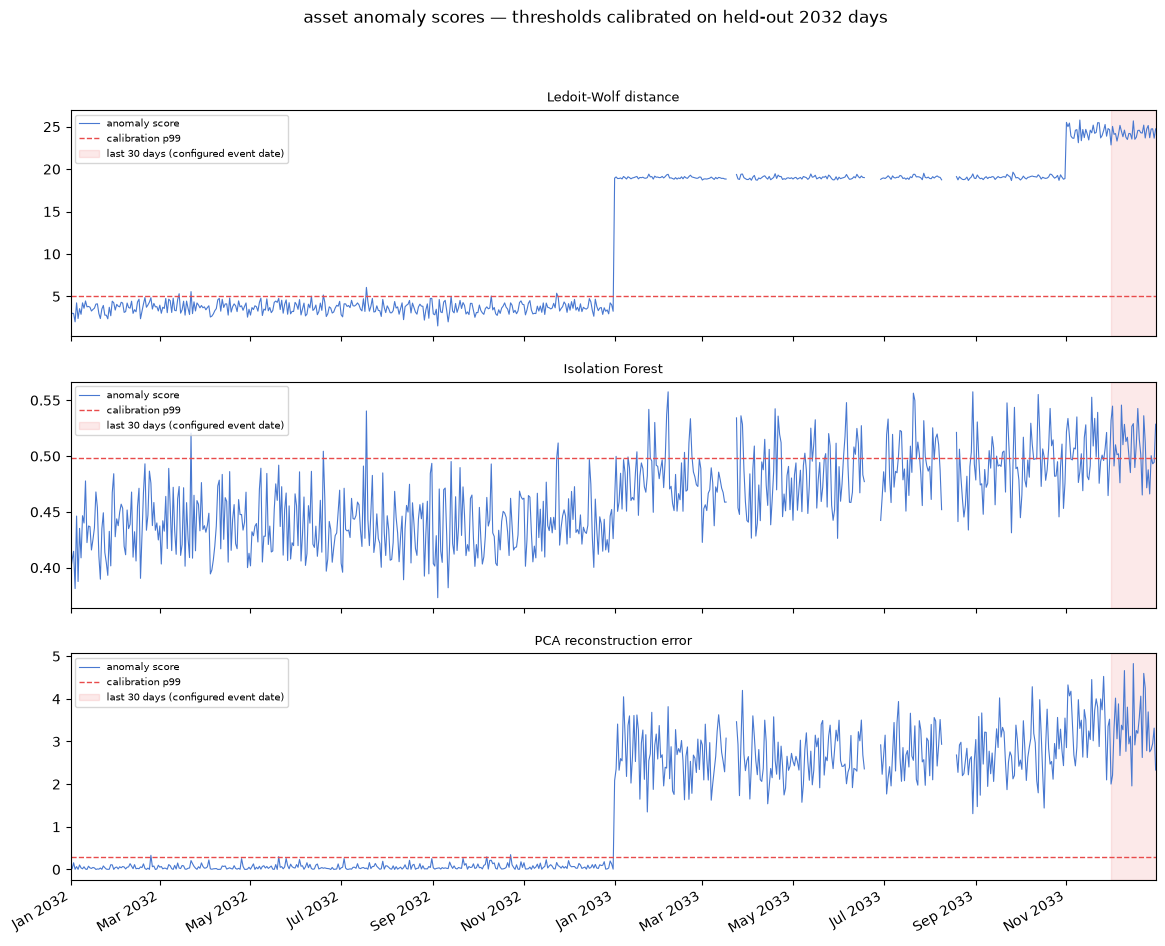

In [5]:
failure_date = pd.Timestamp(cfg['failure_date_used']).normalize()
main_horizon = int(cfg.get('main_horizon', 30))

fig, axes = plt.subplots(len(scores.columns), 1, figsize=(14, 10), sharex=True)

for ax, name in zip(axes, scores.columns):
    ax.plot(scores.index, scores[name], color='#4878D0', lw=0.8, label='anomaly score')

    cal = scores.loc[cal_mask, name].dropna()
    threshold = cal.quantile(0.99)

    ax.axhline(
        threshold,
        color='#E84B4B',
        ls='--',
        lw=1,
        label='calibration p99'
    )

    ax.axvspan(
        failure_date - pd.Timedelta(days=main_horizon),
        failure_date,
        color='#E84B4B',
        alpha=0.12,
        label=f'last {main_horizon} days (configured event date)'
    )

    ax.set_title(name, fontsize=9)
    ax.legend(loc='upper left', fontsize=7)

axes[-1].set_xlim(scores.index.min(), scores.index.max())
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.setp(axes[-1].get_xticklabels(), rotation=30, ha='right')

fig.suptitle('asset anomaly scores — thresholds calibrated on held-out 2032 days')
plt.savefig(FIG_DIR / 'notebook_06_plot_01.png', bbox_inches='tight')
plt.show()

## Analysis step 7

Plot detector scores and alert intervals alongside the configured event window. Compare timing and persistence across methods; a high anomaly score is an unusual pattern, not by itself proof of failure.

In [6]:
evaluation_rows = []
evaluation_start = cal_mask[cal_mask].index.max().normalize() + pd.Timedelta(days=1)

for (model_name, q), sustained in alerts.items():
    episode_start = pd.Series(False, index=sustained.index)

    for sid in state['segment_id'].dropna().unique():
        idx = state.index[state['segment_id'].eq(sid)]
        segment_alert = sustained.loc[idx]
        episode_start.loc[idx] = (
            segment_alert & ~segment_alert.shift(1, fill_value=False)
        )

    alarm_days = sustained[sustained & valid].index.normalize()
    alarm_days = alarm_days[
        (alarm_days >= evaluation_start) &
        (alarm_days <= failure_date)
    ]

    alarm_events = episode_start[episode_start & valid].index.normalize()
    alarm_events = alarm_events[
        (alarm_events >= evaluation_start) &
        (alarm_events <= failure_date)
    ]

    first_alarm = alarm_events.min() if len(alarm_events) else pd.NaT
    lead_days = (
        (failure_date - first_alarm).days
        if pd.notna(first_alarm)
        else np.nan
    )

    horizon_start = failure_date - pd.Timedelta(days=main_horizon)
    events_before_horizon = alarm_events[alarm_events < horizon_start]
    events_inside_horizon = alarm_events[
        (alarm_events >= horizon_start) &
        (alarm_events <= failure_date)
    ]

    days_before_horizon = alarm_days[alarm_days < horizon_start]
    days_inside_horizon = alarm_days[
        (alarm_days >= horizon_start) &
        (alarm_days <= failure_date)
    ]

    evaluation_rows.append({
        'model': model_name,
        'calibration_quantile': q,
        'first_sustained_alarm': first_alarm,
        'lead_days_to_configured_date': lead_days,
        'alarm_episodes_before_horizon': len(events_before_horizon),
        'alarm_episodes_inside_horizon': len(events_inside_horizon),
        'sustained_alarm_days_before_horizon': len(days_before_horizon),
        'sustained_alarm_days_inside_horizon': len(days_inside_horizon),
        'evaluation_start_after_calibration': evaluation_start,
        'configured_event_date_provisional': bool(
            cfg['failure_date_provisional']
        ),
    })

evaluation = pd.DataFrame(evaluation_rows)
evaluation.sort_values(['model', 'calibration_quantile'])

,model,calibration_quantile,first_sustained_alarm,lead_days_to_configured_date,alarm_episodes_before_horizon,alarm_episodes_inside_horizon,sustained_alarm_days_before_horizon,sustained_alarm_days_inside_horizon,evaluation_start_after_calibration,configured_event_date_provisional
3,Isolation Forest,0.950,2033-01-11,354,16,1,107,29,2033-01-01,True
4,Isolation Forest,0.975,2033-06-16,198,7,2,37,22,2033-01-01,True
5,Isolation Forest,0.990,2033-06-16,198,5,1,11,20,2033-01-01,True
0,Ledoit-Wolf distance,0.950,2033-01-05,360,4,0,293,31,2033-01-01,True
1,Ledoit-Wolf distance,0.975,2033-01-05,360,4,0,293,31,2033-01-01,True
2,Ledoit-Wolf distance,0.990,2033-01-05,360,4,0,293,31,2033-01-01,True
6,PCA reconstruction error,0.950,2033-01-05,360,4,0,293,31,2033-01-01,True
7,PCA reconstruction error,0.975,2033-01-05,360,4,0,293,31,2033-01-01,True
8,PCA reconstruction error,0.990,2033-01-05,360,4,0,293,31,2033-01-01,True


In [7]:
summary.to_csv(OUT_DIR / '06_anomaly_calibration_summary.csv', index=False)
evaluation.to_csv(OUT_DIR / '06_anomaly_event_timing.csv', index=False)

print('saved:', OUT_DIR / '06_anomaly_calibration_summary.csv')
print('saved:', OUT_DIR / '06_anomaly_event_timing.csv')

saved: D:\ML_NTI\Predictive Maintanance\predictive-maintenance\reports\tables\06_anomaly_calibration_summary.csv
saved: D:\ML_NTI\Predictive Maintanance\predictive-maintenance\reports\tables\06_anomaly_event_timing.csv


## Analysis step 8

Evaluate calibrated alerts after the baseline period, summarize event timing, and save score summaries and alert episodes for notebook 07.